# PIPELINE: TIỀN XỬ LÝ, HUẤN LUYỆN MODEL & QUẢN TRỊ DOANH THU
### Đề tài: Dự báo Hủy phòng Khách sạn & Tối ưu hóa Doanh thu (Hotel Revenue Management)
---
### Toàn bộ lộ trình thực hiện trong Notebook:
- **PHẦN 1: TIỀN XỬ LÝ DỮ LIỆU & KIỂM ĐỊNH CHẤT LƯỢNG (DATA PREPROCESSING & AUDIT)**
  1. Đọc dữ liệu & khám phá cấu trúc tổng quan (`shape`, `head`, `info`, `describe`).
  2. Lọc riêng phạm vi nghiên cứu: `City Hotel`.
  3. Lập bảng thống kê & vẽ biểu đồ giá trị thiếu (Missing Values).
  4. Xử lý giá trị thiếu: Điền phù hợp hoặc loại bỏ cột thiếu >95% (`company`).
  5. Lọc dữ liệu bất hợp lý (0 khách, 0 đêm, ngoại lai ADR > 1000).
  6. Xóa các biến rò rỉ dữ liệu trực tiếp (`reservation_status`, `reservation_status_date`).
  7. Tạo đặc trưng bổ trợ (`total_nights`, `total_guests`, `arrival_date`) & xuất `hotel_clean.csv`.
- **PHẦN 2: EDA, KPI & KIỂM ĐỊNH THỐNG KÊ**

  8. Phân tích kênh phân phối, tỷ lệ hủy, Occupancy, RevPAR và mùa vụ.
  9. Kiểm định Chi-square và Welch T-test, xuất bảng/biểu đồ EDA.
- **PHẦN 3: HUẤN LUYỆN MÔ HÌNH RANDOM FOREST DỰ BÁO HỦY PHÒNG**

  8. Lựa chọn đặc trưng thuần túy tại thời điểm đặt (Pre-arrival Features) & Danh sách biến cấm (Anti-Leakage).
  9. Mã hóa One-Hot Encoding cho các biến định tính.
  10. Phân chia tập dữ liệu theo thời gian (**Time-based Split**: Học 2015-2016, Kiểm tra 2017).
  11. Huấn luyện mô hình Random Forest Classifier (không dùng `class_weight` để giữ chuẩn xác suất cho bài toán doanh thu).
  12. Đánh giá mô hình: So sánh với Baseline Logistic Regression, ROC-AUC, PR-AUC, Ma trận nhầm lẫn (Confusion Matrix Heatmap), Đường cong ROC.
  13. Phân tích mức độ quan trọng của đặc trưng (Feature Importance).
- **PHẦN 4: THUẬT TOÁN KINH TẾ QUẢN TRỊ DOANH THU (REVENUE MANAGEMENT)**

  14. Mô hình Người bán báo (Newsvendor Model) tính số lượng Overbooking tối ưu.
  15. Quy tắc Littlewood (Littlewood's Rule) phân bổ hạn mức phòng theo 2 hạng giá (xử lý an toàn ngưỡng trượt UI).
  16. Thử nghiệm hàm dự báo xác suất hủy trên các đơn đặt phòng mới (Đồng bộ One-Hot chuẩn xác bằng reindex).


In [1]:
import os
import sys
from pathlib import Path

def _find_project_dir():
    candidates = [Path.cwd(), Path.cwd().parent]
    if Path('/content').exists():
        candidates.extend(Path('/content').glob('*/'))
    for candidate in candidates:
        if (candidate / 'app' / 'app.py').exists() and (candidate / 'data').exists():
            return candidate.resolve()
    raise FileNotFoundError(
        'Không tìm thấy thư mục project. Hãy mở notebook trong project hoặc upload/clone toàn bộ project trên Colab.'
    )

PROJECT_DIR = _find_project_dir()
os.chdir(PROJECT_DIR / 'notebooks')
sys.path.insert(0, str(PROJECT_DIR))
from src.revenue import REVENUE_PARAMS, calculate_overbooking, calculate_littlewood
if sys.stdout.encoding and sys.stdout.encoding.lower() != 'utf-8':
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve, average_precision_score

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option('display.max_columns', None)
print(" Nạp đầy đủ các thư viện cần thiết!")


 Nạp đầy đủ các thư viện cần thiết!


---
# PHẦN 1: TIỀN XỬ LÝ DỮ LIỆU & KIỂM ĐỊNH CHẤT LƯỢNG

## BƯỚC 1: Đọc dữ liệu gốc & Khám phá tổng quan


In [2]:
# 1. Đọc file dữ liệu gốc
df = pd.read_csv("../data/raw/hotel_bookings.csv")

print(f"Tổng số dòng ban đầu: {df.shape[0]:,} dòng")
print(f"Tổng số cột ban đầu:  {df.shape[1]} cột")

df.head()


Tổng số dòng ban đầu: 119,390 dòng
Tổng số cột ban đầu:  32 cột


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# Xem kiểu dữ liệu của các cột
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
# Thống kê mô tả các biến số
df.describe()


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


---
## BƯỚC 2: Lọc dữ liệu riêng cho 'City Hotel'
Đề tài tập trung tối ưu doanh thu cho **City Hotel** (Khách sạn thành phố).


In [5]:
# Lọc riêng City Hotel
df = df[df["hotel"] == "City Hotel"].copy()

print(f"Số dòng của City Hotel: {len(df):,} dòng (chiếm {len(df)/119390*100:.1f}% toàn bộ dữ liệu)")
print(f"Tỷ lệ hủy ban đầu của City Hotel: {df['is_canceled'].mean()*100:.2f}%")


Số dòng của City Hotel: 79,330 dòng (chiếm 66.4% toàn bộ dữ liệu)
Tỷ lệ hủy ban đầu của City Hotel: 41.73%


---
## BƯỚC 3: Kiểm tra giá trị thiếu (Missing Values) cho tất cả các cột


In [6]:
# Bảng kiểm tra missing values cho toàn bộ các cột
null_df = pd.DataFrame({
    'Null Values': df.isna().sum(),
    'Percentage (%)': (df.isna().sum() / len(df)) * 100
})

missing_cols = null_df[null_df['Null Values'] > 0].sort_values(by='Null Values', ascending=False)
missing_cols


,Null Values,Percentage (%)
company,75641,95.349805
agent,8131,10.249590
country,24,0.030253
children,4,0.005042


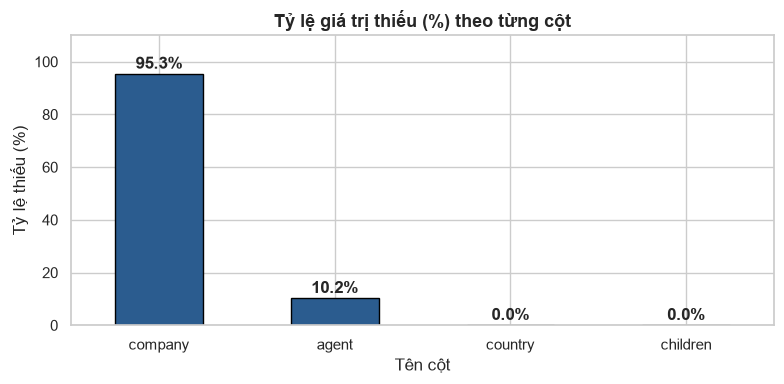

In [7]:
# Vẽ biểu đồ thanh thể hiện tỷ lệ % thiếu
plt.figure(figsize=(8, 4))
ax = missing_cols['Percentage (%)'].plot(kind='bar', color='#2b5c8f', edgecolor='black')
plt.title("Tỷ lệ giá trị thiếu (%) theo từng cột", fontsize=13, fontweight='bold')
plt.ylabel("Tỷ lệ thiếu (%)")
plt.xlabel("Tên cột")
plt.xticks(rotation=0)
plt.ylim(0, 110)

for i, v in enumerate(missing_cols['Percentage (%)']):
    ax.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


---
## BƯỚC 4: Xử lý giá trị thiếu (Missing Values)
- **company**: Thiếu hơn 95% -> Xóa cột, tạo cờ `has_company` để ghi nhớ đơn có doanh nghiệp liên kết.
- **country**: Tên quốc gia -> Điền `'Unknown'`.
- **agent**: Mã đại lý -> Tạo cờ `has_agent`, điền `0` cho đơn đặt trực tiếp.
- **children**: Số lượng trẻ em -> Điền `0`.


In [8]:
# 1. Tạo cờ ghi nhận có công ty / đại lý hay không
df['has_company'] = df['company'].notna().astype(int)
df['has_agent'] = df['agent'].notna().astype(int)

# 2. Xóa cột company vì thiếu hơn 95%
df.drop(columns=['company'], inplace=True, errors='ignore')

# 3. Điền 'Unknown' cho country
df['country'] = df['country'].fillna('Unknown')

# 4. Điền 0 cho children và agent
df['children'] = df['children'].fillna(0).astype(int)
df['agent'] = df['agent'].fillna(0).astype(int)

print("Số giá trị NULL còn lại trong toàn bộ bảng:", df.isna().sum().sum())


Số giá trị NULL còn lại trong toàn bộ bảng: 0


---
## BƯỚC 5: Lọc dữ liệu không dùng được (Dirty Data)
1. **0 khách (167 dòng):** Tổng khách = 0 không tạo ra lưu trú thực tế.
2. **0 đêm (264 dòng):** Đơn không ở đêm nào, không đóng góp công suất phòng-đêm.
3. **ADR > 1000 (1 dòng):** Ngoại lai (5400) , làm biến đổi độ lệch chuẩn.
4. **ADR = 0 (807 đơn):** Giữ lại vì phòng vẫn được chiếm thực tế, gắn cờ `adr_zero` để loại khi tính doanh thu thuần.
5. **`Undefined` ở kênh bán/phân khúc (4 dòng):** Xóa bỏ do không xác định được kênh.


In [9]:
# 1. Lọc đơn không có khách nào
filter_zero_guests = (df['children'] == 0) & (df['adults'] == 0) & (df['babies'] == 0)
print(f"Số đơn không có khách nào : {filter_zero_guests.sum()} dòng")
df = df[~filter_zero_guests]

# 2. Lọc đơn không ở đêm nào
filter_zero_nights = (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0)
print(f"Số đơn không ở đêm nào    : {filter_zero_nights.sum()} dòng")
df = df[~filter_zero_nights]

# 3. Lọc ngoại lai ADR cực đoan (> 1000)
filter_outlier_adr = df['adr'] > 1000
print(f"Số đơn ADR ngoại lai (>1000): {filter_outlier_adr.sum()} dòng")
df = df[~filter_outlier_adr]

# 4. Gắn cờ cho đơn phòng miễn phí (ADR = 0)
df['adr_zero'] = (df['adr'] == 0).astype(int)
print(f"Số đơn phòng miễn phí (ADR = 0) được giữ lại: {df['adr_zero'].sum():,} đơn")

# 5. Chuẩn hóa meal 'Undefined' -> 'SC' và lọc bỏ 'Undefined' ở kênh bán
df['meal'] = df['meal'].replace('Undefined', 'SC')
df = df[(df['market_segment'] != 'Undefined') & (df['distribution_channel'] != 'Undefined')]

print(f"\n-> Tổng số dòng sau khi làm sạch: {len(df):,} dòng")


Số đơn không có khách nào : 167 dòng
Số đơn không ở đêm nào    : 264 dòng
Số đơn ADR ngoại lai (>1000): 1 dòng
Số đơn phòng miễn phí (ADR = 0) được giữ lại: 807 đơn

-> Tổng số dòng sau khi làm sạch: 78,894 dòng


---
## BƯỚC 6: Loại bỏ cột Rò rỉ dữ liệu (Data Leakage)
Hai cột `reservation_status` (Check-Out/Canceled) và `reservation_status_date` được ghi nhận **sau khi sự kiện hủy hoặc trả phòng đã diễn ra**. Đưa vào mô hình sẽ dẫn đến rò rỉ dữ liệu nghiêm trọng.


In [10]:
# Xóa 2 cột rò rỉ dữ liệu trực tiếp
leakage_cols = ['reservation_status', 'reservation_status_date']
df.drop(columns=leakage_cols, inplace=True, errors='ignore')

print("Đã xóa hoàn toàn 2 cột rò rỉ trực tiếp:", leakage_cols)


Đã xóa hoàn toàn 2 cột rò rỉ trực tiếp: ['reservation_status', 'reservation_status_date']


---
## BƯỚC 7: Tạo các đặc trưng bổ trợ & Xuất file `hotel_clean.csv`


In [11]:
# 1. Tổng số đêm lưu trú
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

# 2. Tổng số khách
df['total_guests'] = df['adults'] + df['children'] + df['babies']

# 3. Định dạng ngày đến (arrival_date) chuẩn YYYY-MM-DD
month_map = {
    "January": "01", "February": "02", "March": "03", "April": "04",
    "May": "05", "June": "06", "July": "07", "August": "08",
    "September": "09", "October": "10", "November": "11", "December": "12"
}
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'].map(month_map) + '-' +
    df['arrival_date_day_of_month'].astype(str).str.zfill(2)
)

# 4. Xuất ra file sạch bàn giao
df.to_csv("../data/processed/hotel_clean.csv", index=False)

print("=" * 60)
print(" TIỀN XỬ LÝ HOÀN TẤT VÀ XUẤT FILE THÀNH CÔNG!")
print("=" * 60)
print(f"Tên file đã lưu     : hotel_clean.csv")
print(f"Số dòng dữ liệu sạch: {len(df):,} dòng")
print(f"Số cột dữ liệu      : {df.shape[1]} cột")
print(f"Tỷ lệ hủy phòng     : {df['is_canceled'].mean()*100:.2f}%")
print("=" * 60)


 TIỀN XỬ LÝ HOÀN TẤT VÀ XUẤT FILE THÀNH CÔNG!
Tên file đã lưu     : hotel_clean.csv
Số dòng dữ liệu sạch: 78,894 dòng
Số cột dữ liệu      : 35 cột
Tỷ lệ hủy phòng     : 41.91%


---
# PHẦN 3: HUẤN LUYỆN MÔ HÌNH RANDOM FOREST DỰ BÁO HỦY PHÒNG

## BƯỚC 8: Lựa chọn đặc trưng tại thời điểm đặt (Pre-arrival Features)
Để mô hình ứng dụng được trong thực tế khi khách vừa gửi yêu cầu đặt phòng, ta loại bỏ các biến hậu kiểm (Post-booking features):
- `assigned_room_type`, `is_room_type_changed`, `booking_changes` (khách đến check-in mới phát sinh việc đổi phòng).
- `agent`, `company` (tránh quá tải số chiều ID, đã dùng cờ `has_agent`, `has_company`).
- `arrival_date` (dạng chuỗi thời gian, dùng để chia train/test theo thời gian).


In [12]:
# 1. Danh sách biến gây rò rỉ dữ liệu (Leakage Blacklist)
LEAKAGE_BLACKLIST = [
    "reservation_status", "reservation_status_date",
    "assigned_room_type", "is_room_type_changed", "booking_changes",
    "company", "agent", "arrival_date"
]

# 2. Đặc trưng số (Numerical)
num_features = [
    "lead_time", "total_nights", "total_guests", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "days_in_waiting_list", "adr", "adr_zero", "has_agent", "has_company"
]

# 3. Đặc trưng phân loại (Categorical)
cat_features = [
    "meal", "market_segment", "distribution_channel",
    "deposit_type", "customer_type", "reserved_room_type"
]

# Lọc các biến thực tế có trong dữ liệu
num_features = [f for f in num_features if f in df.columns and f not in LEAKAGE_BLACKLIST]
cat_features = [f for f in cat_features if f in df.columns and f not in LEAKAGE_BLACKLIST]

X = df[num_features + cat_features].copy()
y = df["is_canceled"].copy()

# 4. One-Hot Encoding cho toàn bộ tập dữ liệu
X_encoded = pd.get_dummies(X, columns=cat_features, drop_first=True)
feature_names = X_encoded.columns.tolist()

print(f"Số biến số (Numerical)        : {len(num_features)}")
print(f"Số biến phân loại (Categorical): {len(cat_features)}")
print(f"Tổng số đặc trưng sau One-Hot  : {len(feature_names)} features")


Số biến số (Numerical)        : 14
Số biến phân loại (Categorical): 6
Tổng số đặc trưng sau One-Hot  : 37 features


---
## BƯỚC 9: Phân chia tập dữ liệu theo thời gian (Time-based Split)
- **Lý do:** Giảm rò rỉ vì các đơn trùng cùng ngày đến nằm cùng một phía, nhưng không loại bỏ hết mọi rủi ro (do bản chất khách đoàn có thể phát sinh thêm các đơn đặt rải rác).
- **Phương pháp:** Chia theo dòng thời gian thực tế:
  - **Tập Train:** Toàn bộ đơn có ngày đến trước năm 2017 (`arrival_date < '2017-01-01'`) gồm các năm 2015 và 2016.
  - **Tập Test:** Toàn bộ đơn của năm 2017 (`arrival_date >= '2017-01-01'`) để kiểm tra năng lực dự báo tương lai.


In [13]:
train_mask = df["arrival_date"] < "2017-01-01"

X_train, X_test = X_encoded[train_mask], X_encoded[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print(f"Tập Train (2015-2016): {len(X_train):,} mẫu (Tỷ lệ hủy: {y_train.mean()*100:.2f}%)")
print(f"Tập Test  (2017)     : {len(X_test):,} mẫu (Tỷ lệ hủy: {y_test.mean()*100:.2f}%)")


Tập Train (2015-2016): 51,498 mẫu (Tỷ lệ hủy: 41.52%)
Tập Test  (2017)     : 27,396 mẫu (Tỷ lệ hủy: 42.62%)


---
## BƯỚC 10: Huấn luyện mô hình Random Forest Classifier
- Sử dụng 100 cây quyết định (`n_estimators=100`), giới hạn độ sâu `max_depth=16` để tránh overfitting.
- **Không sử dụng `class_weight='balanced'`:** Vì tỷ lệ hủy (42% vs 58%) không bị mất cân bằng nghiêm trọng. Việc không bật `balanced` giúp giữ chuẩn phân phối xác suất dự báo tự nhiên, phục vụ cho thuật toán tính tiền Overbooking.


In [14]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("Đang huấn luyện mô hình Random Forest...")
rf_model.fit(X_train, y_train)
print(" Huấn luyện thành công!")


Đang huấn luyện mô hình Random Forest...


 Huấn luyện thành công!


---
## BƯỚC 11: Đánh giá mô hình & So sánh với Baseline Logistic Regression
1. **Mô hình cơ sở (Baseline):** Huấn luyện Logistic Regression kèm chuẩn hóa `StandardScaler` để làm mốc đối chứng tối thiểu (mô hình đơn giản đã đạt phần lớn hiệu quả với AUC ~0.788).
2. **ROC-AUC:** Random Forest đạt 0.8117, cao hơn khoảng 0.024 điểm AUC so với Baseline Logistic (0.7881).
3. **PR-AUC:** Random Forest đạt 0.7981 so với mức nền 0.426 (tỷ lệ hủy thực tế trong tập test là 42.6%).
4. **Độ chính xác (Accuracy):** Đạt 72.67%, cần đối chiếu với phương án cơ sở luôn đoán 'Không hủy' (đạt 57.4%).
5. **Trực quan hóa:** Ma trận nhầm lẫn (Confusion Matrix Heatmap) & Đường cong ROC Curve.


 Baseline Logistic AUC  : 0.7881
 Random Forest ROC-AUC  : 0.8117 (cao hơn khoảng 0.024 điểm AUC; mô hình đơn giản đã đạt phần lớn hiệu quả)
 Random Forest PR-AUC   : 0.7981 (so với mức nền 0.426)
 Độ chính xác (Accuracy): 72.67% (so với phương án luôn đoán Không hủy: 57.4%)

BÁO CÁO PHÂN LOẠI:
               precision    recall  f1-score   support

Không hủy (0)     0.6885    0.9565    0.8007     15719
Hủy phòng (1)     0.8771    0.4173    0.5655     11677

     accuracy                         0.7267     27396
    macro avg     0.7828    0.6869    0.6831     27396
 weighted avg     0.7689    0.7267    0.7004     27396



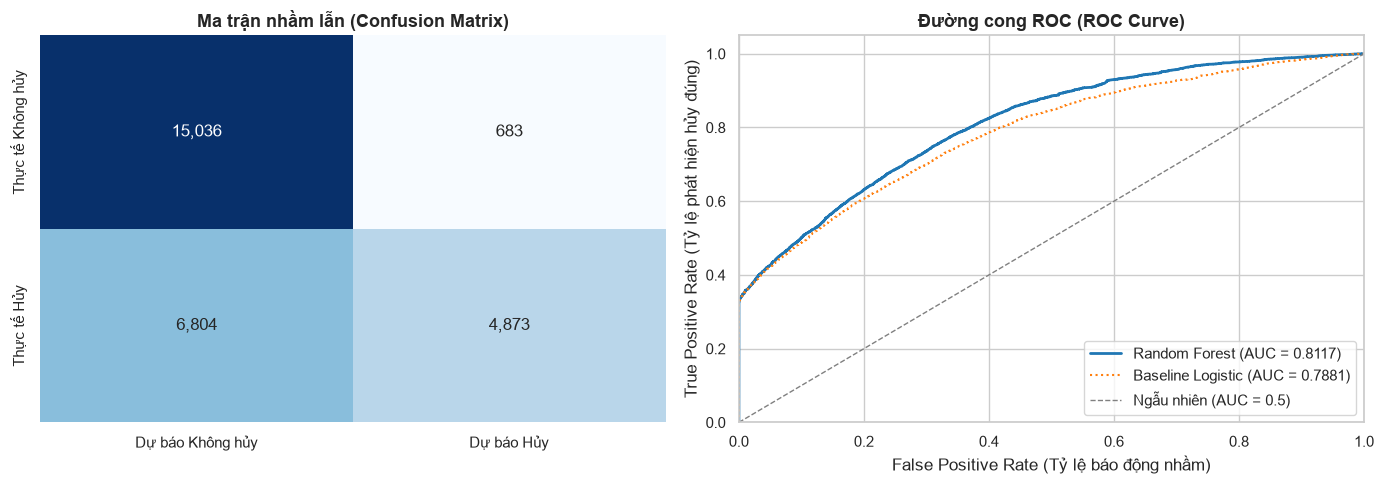

In [15]:
# 1. Huấn luyện Baseline Logistic Regression
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)).fit(X_train, y_train)
lr_prob = lr.predict_proba(X_test)[:, 1]
lr_auc = roc_auc_score(y_test, lr_prob)

# 2. Dự báo bằng Random Forest trên tập Test 2017
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

auc_score = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
acc = (y_pred == y_test).mean()

print("=" * 65)
print(f" Baseline Logistic AUC  : {lr_auc:.4f}")
print(f" Random Forest ROC-AUC  : {auc_score:.4f} (cao hơn khoảng {auc_score - lr_auc:.3f} điểm AUC; mô hình đơn giản đã đạt phần lớn hiệu quả)")
print(f" Random Forest PR-AUC   : {pr_auc:.4f} (so với mức nền 0.426)")
print(f" Độ chính xác (Accuracy): {acc*100:.2f}% (so với phương án luôn đoán Không hủy: {(1 - y_test.mean())*100:.1f}%)")
print("=" * 65)
print("\nBÁO CÁO PHÂN LOẠI:")
print(classification_report(y_test, y_pred, target_names=["Không hủy (0)", "Hủy phòng (1)"], digits=4))

# Trực quan hóa: Ma trận nhầm lẫn & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=["Dự báo Không hủy", "Dự báo Hủy"],
            yticklabels=["Thực tế Không hủy", "Thực tế Hủy"])
axes[0].set_title("Ma trận nhầm lẫn (Confusion Matrix)", fontsize=13, fontweight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)

axes[1].plot(fpr, tpr, color='#1f77b4', lw=2, label=f'Random Forest (AUC = {auc_score:.4f})')
axes[1].plot(lr_fpr, lr_tpr, color='#ff7f0e', lw=1.5, linestyle=':', label=f'Baseline Logistic (AUC = {lr_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='grey', lw=1, linestyle='--', label='Ngẫu nhiên (AUC = 0.5)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (Tỷ lệ báo động nhầm)')
axes[1].set_ylabel('True Positive Rate (Tỷ lệ phát hiện hủy đúng)')
axes[1].set_title('Đường cong ROC (ROC Curve)', fontsize=13, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


---
## BƯỚC 12: Phân tích mức độ quan trọng của đặc trưng (Feature Importance)
- **Ý nghĩa:** Mức độ quan trọng của đặc trưng (Feature Importance) chỉ phản ánh giá trị đóng góp cho việc **dự báo (correlation)** của mô hình, không đồng nghĩa với quan hệ **nhân quả (causality)**.
- **Lưu ý xác suất:** Xác suất trong `model_bundle.pkl` là xác suất thô từ Random Forest (chưa qua hiệu chỉnh calibration), cần lưu ý khi đưa trực tiếp vào công thức tính tiền của các thuật toán doanh thu.


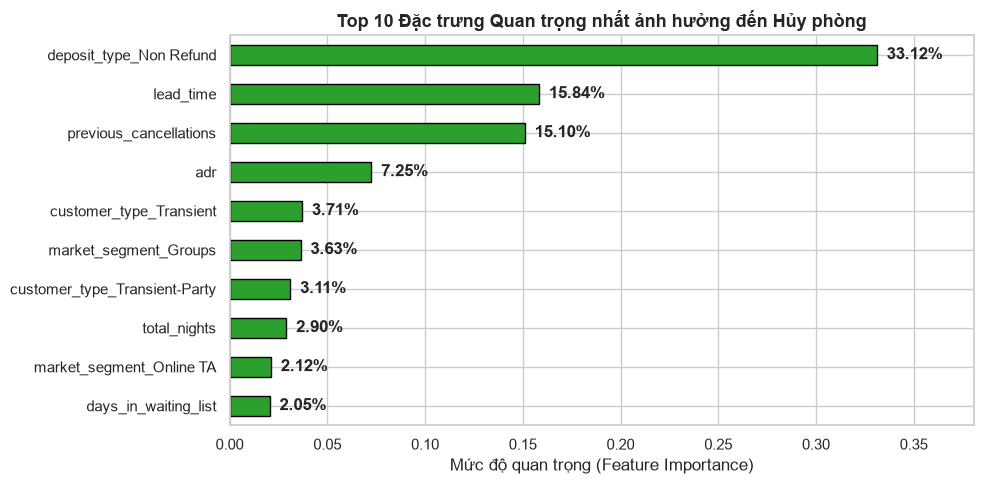

 Đã lưu thành công: 'model_bundle.pkl' và 'feature_importance.csv'


In [16]:
importances = rf_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

# Vẽ biểu đồ Top 10 đặc trưng quan trọng nhất
plt.figure(figsize=(10, 5))
top10 = feat_imp.head(10).sort_values(ascending=True)
ax = top10.plot(kind='barh', color='#2ca02c', edgecolor='black')
plt.title("Top 10 Đặc trưng Quan trọng nhất ảnh hưởng đến Hủy phòng", fontsize=13, fontweight='bold')
plt.xlabel("Mức độ quan trọng (Feature Importance)")

for i, v in enumerate(top10):
    ax.text(v + 0.005, i, f"{v*100:.2f}%", va='center', fontweight='bold')

plt.xlim(0, max(top10) * 1.15)
plt.tight_layout()
plt.show()

# Đóng gói Model Bundle và xuất Feature Importance
bundle = {
    "model": rf_model,
    "feature_names": feature_names,
    "num_features": num_features,
    "cat_features": cat_features,
    "auc_score": auc_score,
    "pr_auc": pr_auc,
    "lr_auc": lr_auc,
    "test_start_date": "2017-01-01"
}
joblib.dump(bundle, "../models/model_bundle.pkl")
feat_imp.head(15).to_csv("../reports/feature_importance.csv", header=["importance"])
print(" Đã lưu thành công: 'model_bundle.pkl' và 'feature_importance.csv'")


---
# PHẦN 4: THUẬT TOÁN QUẢN TRỊ DOANH THU (REVENUE MANAGEMENT)

## BƯỚC 13: Hai thuật toán kinh tế 
1. **Mô hình Người bán báo (Newsvendor Model) cho Overbooking:**
   - $C_u$ (Underage Cost): Chi phí cơ hội khi để trống 1 phòng (= $ADR$).
   - $C_o$ (Overage Cost): Chi phí đền bù Walk Cost khi khách đến mà hết phòng (= $1.5 \times ADR$).
   - Tỷ số tới hạn: $CR = \frac{C_u}{C_u + C_o}$.
   - Số phòng Overbook tối ưu: $Q^* = \mu + z \cdot \sigma$.
2. **Quy tắc Littlewood (Littlewood's Rule) phân bổ công suất 2 hạng giá:**
   - Ngưỡng xác suất bảo vệ: $P(D_{\text{high}} > y^*) = \frac{p_{\text{low}}}{p_{\text{high}}}$.
   - Số phòng giữ lại riêng cho giá cao: $y^* = \mu_{\text{high}} + z \cdot \sigma_{\text{high}}$.
   - Hạn mức bán giá thấp: $\text{Booking Limit} = \text{Capacity} - y^*$.
   - *Xử lý an toàn:* Trả về 0 phòng bảo vệ nếu giá cao $\le$ giá thấp để tránh làm sập giao diện dashboard.


In [17]:
# Chạy thử nghiệm với các tham số giả định minh họa
print("=== THỬ NGHIỆM THUẬT TOÁN DOANH THU (VÍ DỤ MINH HỌA) ===")
res_ob = calculate_overbooking(mean_cancels=REVENUE_PARAMS['mean_cancel'], std_cancels=REVENUE_PARAMS['std_cancel'], adr=REVENUE_PARAMS['adr'], walk_cost_multiplier=REVENUE_PARAMS['walk_cost_multiplier'])
print(f"1. Overbooking theo tham số EDA: cho phép nhận đặt vượt mức {res_ob['overbook_rooms']} phòng.")

low_net = REVENUE_PARAMS['p_low_gross'] * (1 - REVENUE_PARAMS['commission'])
res_lw = calculate_littlewood(p_high=REVENUE_PARAMS['p_high'], p_low=low_net, mean_demand_high=REVENUE_PARAMS['mean_demand_high'], std_demand_high=REVENUE_PARAMS['std_demand_high'], capacity=REVENUE_PARAMS['capacity'])
print(f"2. Littlewood theo tham số EDA: giữ lại {res_lw['protection_level']} phòng giá cao, mở bán {res_lw['booking_limit_low']} phòng giá thấp.")

=== THỬ NGHIỆM THUẬT TOÁN DOANH THU (VÍ DỤ MINH HỌA) ===
1. Overbooking theo tham số EDA: cho phép nhận đặt vượt mức 33 phòng.
2. Littlewood theo tham số EDA: giữ lại 22 phòng giá cao, mở bán 228 phòng giá thấp.


---
## BƯỚC 14: Thử nghiệm dự báo xác suất hủy cho đơn đặt phòng mới (Inference Demo)
*Kỹ thuật chuẩn hóa:* Sử dụng `.reindex(columns=feature_names, fill_value=0)` để tránh lỗi làm mất cột phân loại đơn lẻ khi dùng `pd.get_dummies` trên một dòng dữ liệu mới.


In [18]:
def predict_new_booking(booking_dict):
    input_df = pd.DataFrame([booking_dict])
    # One-Hot Encoding và reindex đồng bộ chuẩn xác với toàn bộ danh sách feature lúc train
    input_encoded = pd.get_dummies(input_df, columns=cat_features).reindex(columns=feature_names, fill_value=0)
    
    prob = rf_model.predict_proba(input_encoded)[0][1]
    return round(prob * 100, 2)

# Ví dụ 1: Khách đặt qua Online TA, đặt trước 150 ngày, không đặt cọc
sample_booking_1 = {
    "lead_time": 150, "adults": 2, "children": 0, "babies": 0, "meal": "BB",
    "market_segment": "Online TA", "distribution_channel": "TA/TO", "reserved_room_type": "A",
    "deposit_type": "No Deposit", "customer_type": "Transient", "adr": 95.0,
    "total_nights": 3, "total_guests": 2, "is_repeated_guest": 0,
    "previous_cancellations": 0, "previous_bookings_not_canceled": 0,
    "days_in_waiting_list": 0, "adr_zero": 0, "has_agent": 1, "has_company": 0
}

# Ví dụ 2: Khách đặt cọc không hoàn tiền (Non Refund), từng hủy 2 lần, lead_time=200
sample_booking_2 = {
    "lead_time": 200, "adults": 2, "children": 1, "babies": 0, "meal": "HB",
    "market_segment": "Online TA", "distribution_channel": "TA/TO", "reserved_room_type": "D",
    "deposit_type": "Non Refund", "customer_type": "Transient", "adr": 120.0,
    "total_nights": 5, "total_guests": 3, "is_repeated_guest": 0,
    "previous_cancellations": 2, "previous_bookings_not_canceled": 0,
    "days_in_waiting_list": 0, "adr_zero": 0, "has_agent": 1, "has_company": 0
}

prob1 = predict_new_booking(sample_booking_1)
prob2 = predict_new_booking(sample_booking_2)

# Thử nghiệm kiểm chứng: Giữ nguyên mọi thông tin của Đơn 1, chỉ đổi No Deposit -> Non Refund
sample_booking_1_nonrefund = sample_booking_1.copy()
sample_booking_1_nonrefund["deposit_type"] = "Non Refund"
prob1_nr = predict_new_booking(sample_booking_1_nonrefund)

print("=" * 70)
print(f"Đơn 1 (Khách lẻ Online TA, lead_time=150, No Deposit)   : {prob1}% xác suất hủy -> {'CẢNH BÁO HỦY' if prob1 >= 50 else 'AN TOÀN'}")
print(f"Đơn 2 (Non Refund, có lịch sử hủy 2 lần, lead_time=200) : {prob2}% xác suất hủy -> {'CẢNH BÁO HỦY' if prob2 >= 50 else 'AN TOÀN'}")
print("-" * 70)
print(f"Kiểm chứng tác động reindex của 'Non Refund' (giữ nguyên đơn 1, chỉ đổi cọc):")
print(f"  No Deposit: {prob1}%  ===>  Non Refund: {prob1_nr}%  (Tăng vọt +{prob1_nr - prob1:.2f}%)")
print("=" * 70)


Đơn 1 (Khách lẻ Online TA, lead_time=150, No Deposit)   : 37.15% xác suất hủy -> AN TOÀN
Đơn 2 (Non Refund, có lịch sử hủy 2 lần, lead_time=200) : 88.58% xác suất hủy -> CẢNH BÁO HỦY
----------------------------------------------------------------------
Kiểm chứng tác động reindex của 'Non Refund' (giữ nguyên đơn 1, chỉ đổi cọc):
  No Deposit: 37.15%  ===>  Non Refund: 89.36%  (Tăng vọt +52.21%)


---
# PHẦN BỔ SUNG: EDA, KPI & KIỂM ĐỊNH THỐNG KÊ

Phần này sử dụng trực tiếp `df` sau preprocessing để tạo các bảng bàn giao cho báo cáo và revenue management.


Bản ghi sạch: 78,894
Peak occupancy quan sát được: 226 phòng (13/08/2016)
Công suất mô phỏng: 250 phòng
Hủy trung bình/ngày: 41.69 ± 35.16
ADR trung bình: 105.79 EUR


,distribution_channel,total_bookings,canceled_count,total_nights,mean_adr,median_lead_time,cancel_rate_%,nights_share_%
0,Corporate,3365,776,6740,85.80,9.0,23.06,2.86
1,Direct,6678,1226,18614,112.45,17.0,18.36,7.90
2,GDS,190,37,378,122.46,11.0,19.47,0.16
3,TA/TO,68661,31022,209760,106.08,86.0,45.18,89.07


,year_month,total_bookings,canceled_bookings,total_nights,occupied_room_nights,room_revenue,days_in_month,available_room_nights,occupancy_%,revpar_eur
0,2015-07,1393,939,3755,1028,75614.09,31,7750,13.26,9.76
1,2015-08,2467,1228,6689,3398,275450.09,31,7750,43.85,35.54
2,2015-09,3516,1542,9625,5541,592053.75,30,7500,73.88,78.94
3,2015-10,3368,1321,8846,5530,522119.25,31,7750,71.35,67.37
4,2015-11,1225,301,3588,2724,197489.38,30,7500,36.32,26.33
5,2015-12,1637,668,4894,2628,207103.64,31,7750,33.91,26.72
6,2016-01,1355,436,3747,2459,194455.18,31,7750,31.73,25.09
7,2016-02,2347,925,6729,3721,306282.94,29,7250,51.32,42.25
8,2016-03,3027,1106,9296,5714,501287.17,31,7750,73.73,64.68
9,2016-04,3549,1537,10257,5796,573929.71,30,7500,77.28,76.52


,lead_time_group,bookings,mean_adr,cancel_rate_%
0,0-7,10508,104.80,12.30
1,8-30,12510,113.56,30.99
2,31-90,20747,107.27,39.99
3,91-180,18200,110.28,48.04
4,181+,16929,94.04,64.10


Chi-square: statistic=2353.69, df=3, p-value=0.0000e+00
Welch T-test ADR: statistic=-7.11, p-value=1.1746e-12


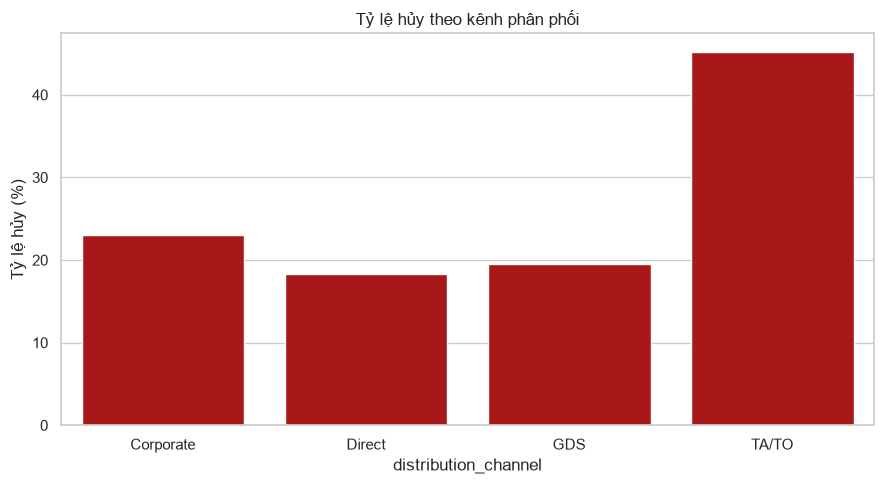

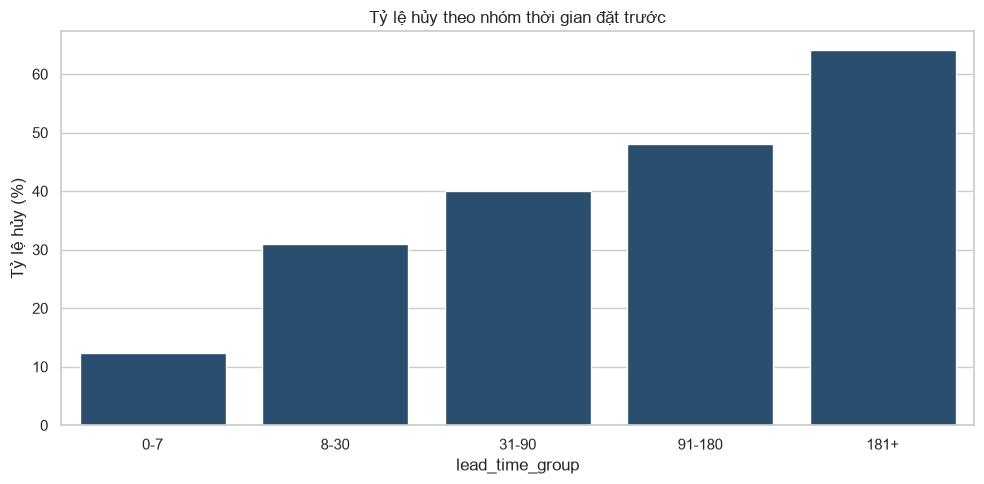

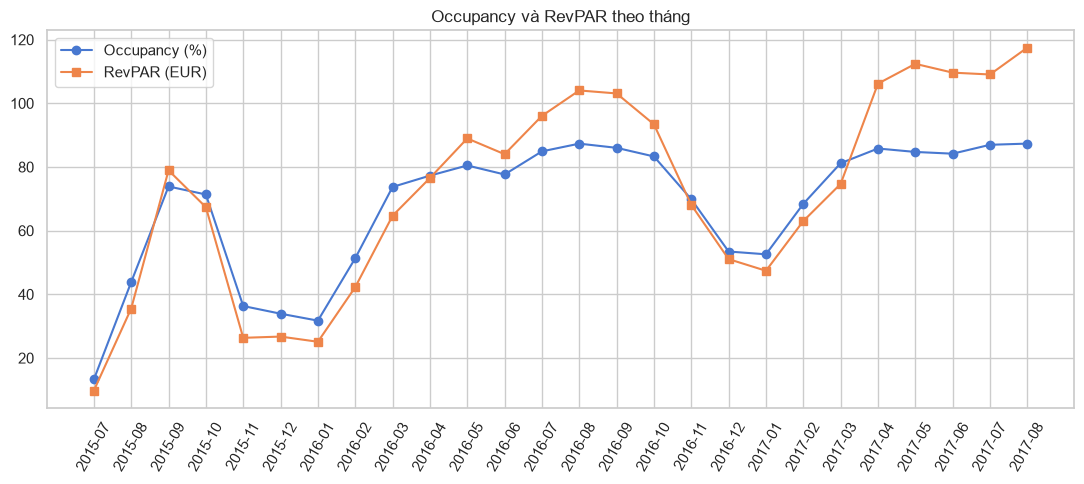

Đã xuất Excel EDA và 3 biểu đồ vào reports/.


In [19]:
from pathlib import Path
from datetime import timedelta
from scipy import stats

PROJECT_DIR = Path('..').resolve()
sys.path.insert(0, str(PROJECT_DIR))
from src.revenue import REVENUE_PARAMS
REPORTS_DIR = PROJECT_DIR / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

actual_stays = df[df['is_canceled'] == 0].copy()
daily_occupied_rooms = {}
for row in actual_stays.itertuples(index=False):
    for offset in range(int(row.total_nights)):
        day = row.arrival_date + timedelta(days=offset)
        daily_occupied_rooms[day] = daily_occupied_rooms.get(day, 0) + 1
peak_date = max(daily_occupied_rooms, key=daily_occupied_rooms.get)
observed_peak_occupancy = daily_occupied_rooms[peak_date]

daily_cancel_counts = df[df['is_canceled'] == 1].groupby('arrival_date').size()
calendar = pd.date_range(df['arrival_date'].min(), df['arrival_date'].max(), freq='D')
daily_cancel_counts = daily_cancel_counts.reindex(calendar, fill_value=0)
mean_daily_cancellations = daily_cancel_counts.mean()
std_daily_cancellations = daily_cancel_counts.std(ddof=1)
mean_adr_clean = df['adr'].mean()
print(f'Bản ghi sạch: {len(df):,}')
print(f'Peak occupancy quan sát được: {observed_peak_occupancy} phòng ({peak_date:%d/%m/%Y})')
print(f'Công suất mô phỏng: {REVENUE_PARAMS["capacity"]} phòng')
print(f'Hủy trung bình/ngày: {mean_daily_cancellations:.2f} ± {std_daily_cancellations:.2f}')
print(f'ADR trung bình: {mean_adr_clean:.2f} EUR')

channel_summary = df.groupby('distribution_channel').agg(total_bookings=('is_canceled', 'count'), canceled_count=('is_canceled', 'sum'), total_nights=('total_nights', 'sum'), mean_adr=('adr', 'mean'), median_lead_time=('lead_time', 'median')).reset_index()
channel_summary['cancel_rate_%'] = channel_summary['canceled_count'] / channel_summary['total_bookings'] * 100
channel_summary['nights_share_%'] = channel_summary['total_nights'] / df['total_nights'].sum() * 100
display(channel_summary.round(2))

occupied_records = []
for row in actual_stays.itertuples(index=False):
    for offset in range(int(row.total_nights)):
        occupied_records.append((row.arrival_date + timedelta(days=offset), row.adr))
occupied_daily = pd.DataFrame(occupied_records, columns=['date', 'adr'])
occupied_monthly = occupied_daily.assign(year_month=occupied_daily['date'].dt.to_period('M')).groupby('year_month').agg(occupied_room_nights=('adr', 'size'), room_revenue=('adr', 'sum')).reset_index()
monthly_kpi = df.assign(year_month=df['arrival_date'].dt.to_period('M')).groupby('year_month').agg(total_bookings=('is_canceled', 'size'), canceled_bookings=('is_canceled', 'sum'), total_nights=('total_nights', 'sum')).reset_index().merge(occupied_monthly, on='year_month', how='left')
monthly_kpi['days_in_month'] = monthly_kpi['year_month'].dt.days_in_month
monthly_kpi['available_room_nights'] = REVENUE_PARAMS['capacity'] * monthly_kpi['days_in_month']
monthly_kpi['occupancy_%'] = monthly_kpi['occupied_room_nights'] / monthly_kpi['available_room_nights'] * 100
monthly_kpi['revpar_eur'] = monthly_kpi['room_revenue'] / monthly_kpi['available_room_nights']
monthly_kpi['year_month'] = monthly_kpi['year_month'].astype(str)
display(monthly_kpi.round(2))

lead_bins = [-1, 7, 30, 90, 180, float('inf')]
lead_labels = ['0-7', '8-30', '31-90', '91-180', '181+']
lead_stats = df.assign(lead_time_group=pd.cut(df['lead_time'], bins=lead_bins, labels=lead_labels)).groupby('lead_time_group', observed=False).agg(bookings=('is_canceled', 'size'), cancel_rate=('is_canceled', 'mean'), mean_adr=('adr', 'mean')).reset_index()
lead_stats['cancel_rate_%'] = lead_stats['cancel_rate'] * 100
display(lead_stats.drop(columns='cancel_rate').round(2))

contingency = pd.crosstab(df['distribution_channel'], df['is_canceled'])
chi2_stat, chi2_p, chi2_df, _ = stats.chi2_contingency(contingency)
welch_stat, welch_p = stats.ttest_ind(df.loc[df['is_canceled'] == 1, 'adr'], df.loc[df['is_canceled'] == 0, 'adr'], equal_var=False)
print(f'Chi-square: statistic={chi2_stat:.2f}, df={chi2_df}, p-value={chi2_p:.4e}')
print(f'Welch T-test ADR: statistic={welch_stat:.2f}, p-value={welch_p:.4e}')

plt.figure(figsize=(9, 5)); sns.barplot(data=channel_summary, x='distribution_channel', y='cancel_rate_%', color='#C00000'); plt.title('Tỷ lệ hủy theo kênh phân phối'); plt.ylabel('Tỷ lệ hủy (%)'); plt.tight_layout(); plt.savefig(FIGURES_DIR / 'channel_comparison.png', dpi=180); plt.show()
plt.figure(figsize=(10, 5)); sns.barplot(data=lead_stats, x='lead_time_group', y='cancel_rate_%', color='#1F4E79'); plt.title('Tỷ lệ hủy theo nhóm thời gian đặt trước'); plt.ylabel('Tỷ lệ hủy (%)'); plt.tight_layout(); plt.savefig(FIGURES_DIR / 'booking_curve.png', dpi=180); plt.show()
plt.figure(figsize=(11, 5)); plt.plot(monthly_kpi['year_month'], monthly_kpi['occupancy_%'], marker='o', label='Occupancy (%)'); plt.plot(monthly_kpi['year_month'], monthly_kpi['revpar_eur'], marker='s', label='RevPAR (EUR)'); plt.xticks(rotation=60); plt.title('Occupancy và RevPAR theo tháng'); plt.legend(); plt.tight_layout(); plt.savefig(FIGURES_DIR / 'monthly_seasonality.png', dpi=180); plt.show()

revenue_params = pd.DataFrame([['clean_records', len(df), 'booking', 'data-derived'], ['mean_daily_cancellations', round(mean_daily_cancellations, 4), 'booking/day', 'data-derived'], ['std_daily_cancellations', round(std_daily_cancellations, 4), 'booking/day', 'data-derived'], ['observed_peak_occupancy', observed_peak_occupancy, 'room', 'data-derived'], ['capacity_scenario', REVENUE_PARAMS['capacity'], 'room', 'assumption'], ['adr_mean_clean', round(mean_adr_clean, 4), 'EUR/room-night', 'data-derived'], ['adr_used_in_revenue', REVENUE_PARAMS['adr'], 'EUR/room-night', 'scenario-input'], ['handoff_overbook_rooms', REVENUE_PARAMS['handoff_overbook_rooms'], 'room', 'handoff-reference']], columns=['parameter', 'value', 'unit', 'source_type'])
df_export = df.copy(); df_export['arrival_date'] = df_export['arrival_date'].dt.strftime('%Y-%m-%d')
with pd.ExcelWriter(REPORTS_DIR / 'bang_du_lieu_va_chi_so_eda.xlsx', engine='openpyxl') as writer:
    channel_summary.to_excel(writer, sheet_name='channel_summary', index=False); monthly_kpi.to_excel(writer, sheet_name='monthly_kpi', index=False); lead_stats.to_excel(writer, sheet_name='lead_stats', index=False); revenue_params.to_excel(writer, sheet_name='revenue_params', index=False); df_export.to_excel(writer, sheet_name='df', index=False)
print('Đã xuất Excel EDA và 3 biểu đồ vào reports/.')


# PHẦN 5: KHỞI CHẠY STREAMLIT DASHBOARD

Notebook này gọi trực tiếp giao diện trong `app/app.py`, vì vậy dashboard và notebook dùng chung model, dữ liệu và các công thức doanh thu.

- Chạy local: cell kế tiếp chỉ in lệnh chạy Streamlit.
- Chạy Google Colab: cần upload hoặc clone **toàn bộ project** (gồm `app/`, `src/`, `data/`, `models/`, `reports/`), sau đó chạy các cell từ đầu. Cell kế tiếp sẽ tạo URL tạm bằng LocalTunnel.

In [20]:
import shutil
import subprocess
import sys
import time

APP_FILE = PROJECT_DIR / 'app' / 'app.py'
if not APP_FILE.exists():
    raise FileNotFoundError(
        f'Không tìm thấy {APP_FILE}. Hãy mở notebook từ project hoặc upload/clone toàn bộ project trên Colab.'
    )

# Cho phép chạy lại cell mà không để sót các process cũ.
for _process_name in ('tunnel_process', 'streamlit_process'):
    _old_process = globals().get(_process_name)
    if _old_process is not None and _old_process.poll() is None:
        _old_process.terminate()

IN_COLAB = 'google.colab' in sys.modules
if not IN_COLAB:
    print(f'Chạy dashboard bằng lệnh: python -m streamlit run {APP_FILE}')
    print('Notebook đã hoàn tất; mở lệnh trên ở terminal để xem giao diện.')
else:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'streamlit'])
    if shutil.which('npx') is None:
        raise RuntimeError('Colab không có npx. Hãy bật runtime mới rồi chạy lại cell này.')

    streamlit_process = subprocess.Popen(
        [
            sys.executable, '-m', 'streamlit', 'run', str(APP_FILE),
            '--server.port', '8501',
            '--server.address', '0.0.0.0',
            '--server.headless', 'true',
        ],
        cwd=PROJECT_DIR,
    )
    time.sleep(5)
    tunnel_process = subprocess.Popen(['npx', '--yes', 'localtunnel', '--port', '8501'])
    print('Streamlit đang chạy. URL public của LocalTunnel sẽ xuất hiện trong output bên dưới.')
    print('Giữ runtime Colab còn hoạt động trong lúc trình diễn; URL sẽ hết hiệu lực khi runtime dừng.')

Chạy dashboard bằng lệnh: python -m streamlit run C:\Users\phucd\Downloads\PreprocessingandPrediction\preprocessingvisualized\app\app.py
Notebook đã hoàn tất; mở lệnh trên ở terminal để xem giao diện.
